# P3 Movie Genre, Notebook 3: Interpretability (xAI)
**Team:** DataStars &nbsp;|&nbsp; **Course:** MSDS 565, Unit 3 Text Classification

Notebook 2 measured how well the models do. This notebook asks what they are doing. It uses the three TF-IDF logistic regression models (Comedy, Horror, Romance) trained on IMDB labels in Notebook 2, and explains them in three ways: the **coefficients** (what the model learned overall), **SHAP values** (what drove predictions on the test set) and **waterfall plots** (what drove single predictions).

**To run this notebook:** run Notebook 2 first so that `models/` holds the vectorizer, the scaler and the three TF-IDF models, and install SHAP in the course environment (`pip install shap`). Re-export `environment.yml` afterwards (`conda env export --no-builds > environment.yml`).

## 1. Setup

The notebook rebuilds exactly what Notebook 2 used: the same vote filter (`MIN_VOTES = 500`), the same credit-line cleaning, the provided `train` + `val` rows as the training set and the `test` rows as the test set. It then loads the fitted TF-IDF vectorizer, the fitted `StandardScaler` and the three models from `models/`. Nothing is refit here. The training set is only used as the background data for SHAP (see section 3).

As a safety check, the test macro-F1 of each loaded model is recomputed. It should match the TF-IDF (IMDB labels) row of the Notebook 2 leaderboard (Comedy 0.789, Horror 0.876, Romance 0.743), which proves the loaded files are the Notebook 2 models and that the test set is the same.

In [1]:
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from scipy.stats import spearmanr
from sklearn.metrics import f1_score

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')

MIN_VOTES = 500                      # decided in Notebook 1
GENRES = ['Comedy', 'Horror', 'Romance']
DATA_PATH = Path.home() / 'MSDS565_data' / 'mpst_imdb_movies.csv'      # provided CSV, kept outside the repo
MODELS_DIR = Path('..') / 'models'                                      # written by Notebook 2

CREDIT = re.compile(
    r"\[?\s*(?:(?:original|full)\s+)?(?:synopsis|summary)\s+(?:written\s+)?by\s+[\w.\-]+(?:\s[\w.\-]+)?\s*[.\]]?"
    r"|\[\s*[A-Za-z][\w\-]*\d[\w\-]*\s*\]"
    r"|[-_]{2,}\s*(?:written by\s+\w+|\w+'s synopsis:)"
    r"|krystel\s?clai?re|bj[_ ]?kuehl|mu_ve_watchr_89",
    flags=re.IGNORECASE)

df = pd.read_csv(DATA_PATH)
movies = df[df['numVotes'] >= MIN_VOTES].reset_index(drop=True)
movies['text'] = movies['plot_synopsis'].map(lambda t: CREDIT.sub(' ', t))
is_test = (movies['split'] == 'test').to_numpy()
train = movies[~is_test].reset_index(drop=True)      # train + val
test = movies[is_test].reset_index(drop=True)
print(f"Vote filter: {len(df):,} -> {len(movies):,} movies | training set {len(train):,} | test set {len(test):,}")

tfidf = joblib.load(MODELS_DIR / 'P3_N2_tfidf_vectorizer.pkl')
scaler = joblib.load(MODELS_DIR / 'P3_N2_tfidf_scaler.pkl')
models = {g: joblib.load(MODELS_DIR / f'P3_N2_tfidf_logreg_{g.lower()}.pkl') for g in GENRES}
vocab = tfidf.get_feature_names_out()

Xtr = scaler.transform(tfidf.transform(train['text']))      # standardized TF-IDF, as in Notebook 2
Xte = scaler.transform(tfidf.transform(test['text']))
doc_freq = pd.Series(np.asarray((Xte > 0).sum(axis=0)).ravel() / Xte.shape[0], index=vocab)   # share of test synopses containing each word

NB2_TEST_F1 = {'Comedy': 0.789, 'Horror': 0.876, 'Romance': 0.743}      # from the Notebook 2 leaderboard
check = pd.DataFrame({'test macro-F1 (recomputed)': {g: f1_score(test[g], models[g].predict(Xte), average='macro') for g in GENRES},
                      'Notebook 2 leaderboard': NB2_TEST_F1}).round(3)
assert (check.iloc[:, 0] - check.iloc[:, 1]).abs().max() < 0.02, 'loaded models do not match Notebook 2'
check

Vote filter: 11,824 -> 11,089 movies | training set 8,880 | test set 2,209


,test macro-F1 (recomputed),Notebook 2 leaderboard
Comedy,0.789,0.789
Horror,0.876,0.876
Romance,0.743,0.743


## 2. Coefficients

A logistic regression scores a synopsis as `intercept + sum(coefficient x feature value)` and turns that score into a probability. A **positive coefficient** pushes a synopsis toward the genre when the word is present, and a **negative coefficient** pushes it away. Because every TF-IDF column was standardized to unit variance in Notebook 2, one unit of any word means the same thing, so coefficient sizes can be compared across words directly (without standardization a rare word would get a large coefficient only because its raw values are small).

For each genre the plot shows the 10 words with the largest positive coefficients (green) and the 10 with the most negative coefficients (red).

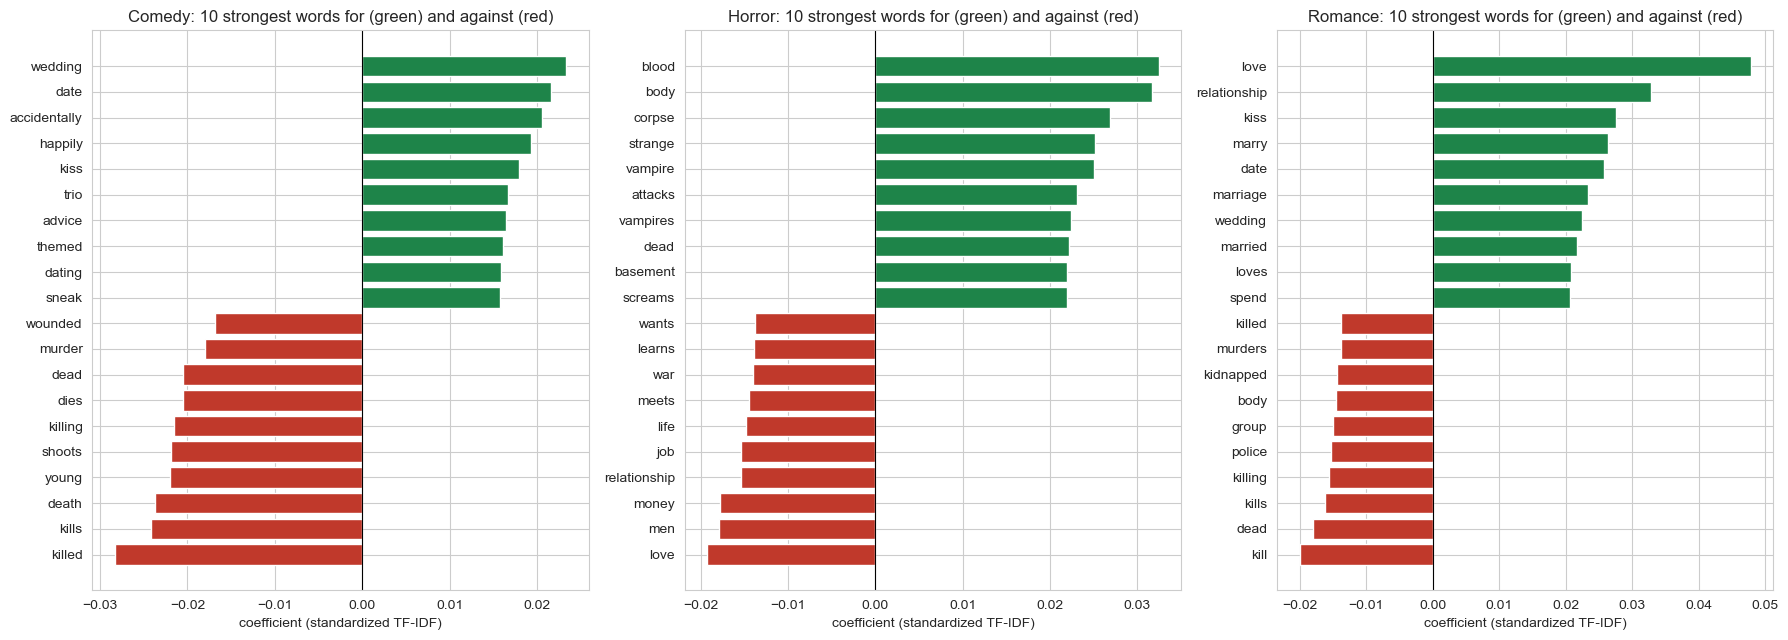

Largest positive coefficients
                     Comedy             Horror                Romance
rank                                                                 
1          wedding (+0.023)     blood (+0.032)          love (+0.048)
2             date (+0.022)      body (+0.032)  relationship (+0.033)
3     accidentally (+0.021)    corpse (+0.027)          kiss (+0.028)
4          happily (+0.019)   strange (+0.025)         marry (+0.026)
5             kiss (+0.018)   vampire (+0.025)          date (+0.026)
6             trio (+0.017)   attacks (+0.023)      marriage (+0.023)
7           advice (+0.016)  vampires (+0.022)       wedding (+0.022)
8           themed (+0.016)      dead (+0.022)       married (+0.022)
9           dating (+0.016)  basement (+0.022)         loves (+0.021)
10           sneak (+0.016)   screams (+0.022)         spend (+0.021)

Most negative coefficients
                Comedy                 Horror             Romance
rank                                

In [2]:
coefs = {g: pd.Series(models[g].coef_[0], index=vocab) for g in GENRES}

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, g in zip(axes, GENRES):
    top = pd.concat([coefs[g].nlargest(10), coefs[g].nsmallest(10)]).sort_values()
    ax.barh(top.index, top.values, color=['#c0392b' if v < 0 else '#1e8449' for v in top.values])
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{g}: 10 strongest words for (green) and against (red)')
    ax.set_xlabel('coefficient (standardized TF-IDF)')
plt.tight_layout()
plt.show()

pd.DataFrame({g: [f'{w} ({v:+.3f})' for w, v in coefs[g].nlargest(10).items()] for g in GENRES}).rename_axis('rank').rename(lambda i: i + 1).pipe(
    lambda t: print('Largest positive coefficients\n' + t.to_string() + '\n'))
pd.DataFrame({g: [f'{w} ({v:+.3f})' for w, v in coefs[g].nsmallest(10).items()] for g in GENRES}).rename_axis('rank').rename(lambda i: i + 1).pipe(
    lambda t: print('Most negative coefficients\n' + t.to_string()))

**What the coefficients say.** The words are sensible, which is the first thing to check. For **Horror** the words that push toward the genre are physical and threatening (`blood`, `body`, `corpse`, `vampire`, `attacks`, `screams`, `basement`), and the words that push away are everyday story words (`love`, `money`, `relationship`, `job`, `life`). **Romance** is close to the mirror image: `love`, `relationship`, `kiss`, `marry`, `wedding` push toward it, and violence and crime words (`kill`, `dead`, `police`, `body`) push away. **Comedy** has the softest evidence of the three: its positive words are light social words (`wedding`, `date`, `accidentally`, `happily`, `dating`), while its strongest negatives are violence words (`killed`, `kills`, `death`, `shoots`, `dies`). In other words the Comedy model is largely a "not violent, social" detector, because no single word says "funny" the way `vampire` says "horror". This matches the Notebook 1 prediction and the Notebook 2 results: Horror has the largest coefficients and the best test score, while Comedy and Romance rely on weaker words and score lower.

Two cautions. First, the coefficients are small overall (the largest are only about 0.02 to 0.05) because Notebook 2 chose a very strong regularization (`C = 0.0001`) for the standardized TF-IDF features. The sizes are comparable across words, but they are not probabilities. Second, a coefficient describes the word in isolation. It does not say how often the word appears, which is the subject of the next section.

## 3. SHAP

SHAP assigns each word in each test synopsis a share of that prediction. For a linear model the calculation is exact and simple: the contribution of word *j* in synopsis *i* is `coefficient_j x (x_ij - mean_j)`, where `mean_j` is the average value of the word in a **background** set (here the training set). The contributions of all 20,000 words add up to the model's log-odds for the synopsis minus the base value (the average log-odds over the background). `LinearExplainer` computes this directly.

A coefficient is a property of the model, but a SHAP value is a property of the model **applied to real synopses**. A word with a large coefficient that almost never appears is large in the first and close to zero in the second. SHAP is computed for all three genres on the full test set. The cell checks that the contributions really add up to the model's score.

In [3]:
shap_store = {}
for g in GENRES:
    explainer = shap.LinearExplainer(models[g], shap.maskers.Independent(Xtr, max_samples=Xtr.shape[0]))   # background = whole training set
    sv = explainer.shap_values(Xte)                                    # test synopses x 20,000 words
    gap = np.abs(sv.sum(axis=1) + explainer.expected_value - models[g].decision_function(Xte)).max()
    assert gap < 1e-6, 'SHAP values do not add up to the model score'
    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=vocab)
    top = np.argsort(-mean_abs.to_numpy())[:15]                        # keep only what the plots need, to save memory
    shap_store[g] = {'explainer': explainer, 'mean_abs': mean_abs, 'top_idx': top,
                     'top_values': sv[:, top], 'top_data': Xte[:, top].toarray()}
    del sv
    print(f'{g}: SHAP computed for {Xte.shape[0]:,} synopses, additivity gap {gap:.1e}, base value {explainer.expected_value:+.3f}')

Comedy: SHAP computed for 2,209 synopses, additivity gap 8.4e-15, base value -0.585
Horror: SHAP computed for 2,209 synopses, additivity gap 5.3e-15, base value -1.122
Romance: SHAP computed for 2,209 synopses, additivity gap 8.0e-15, base value -0.937


### 3.1 Bar plot: mean |SHAP| per word

The bar length is the average size of a word's contribution (in either direction) over all test synopses. It combines how strong the word is with how often it shows up. Each panel shows the 15 words with the largest mean |SHAP|.

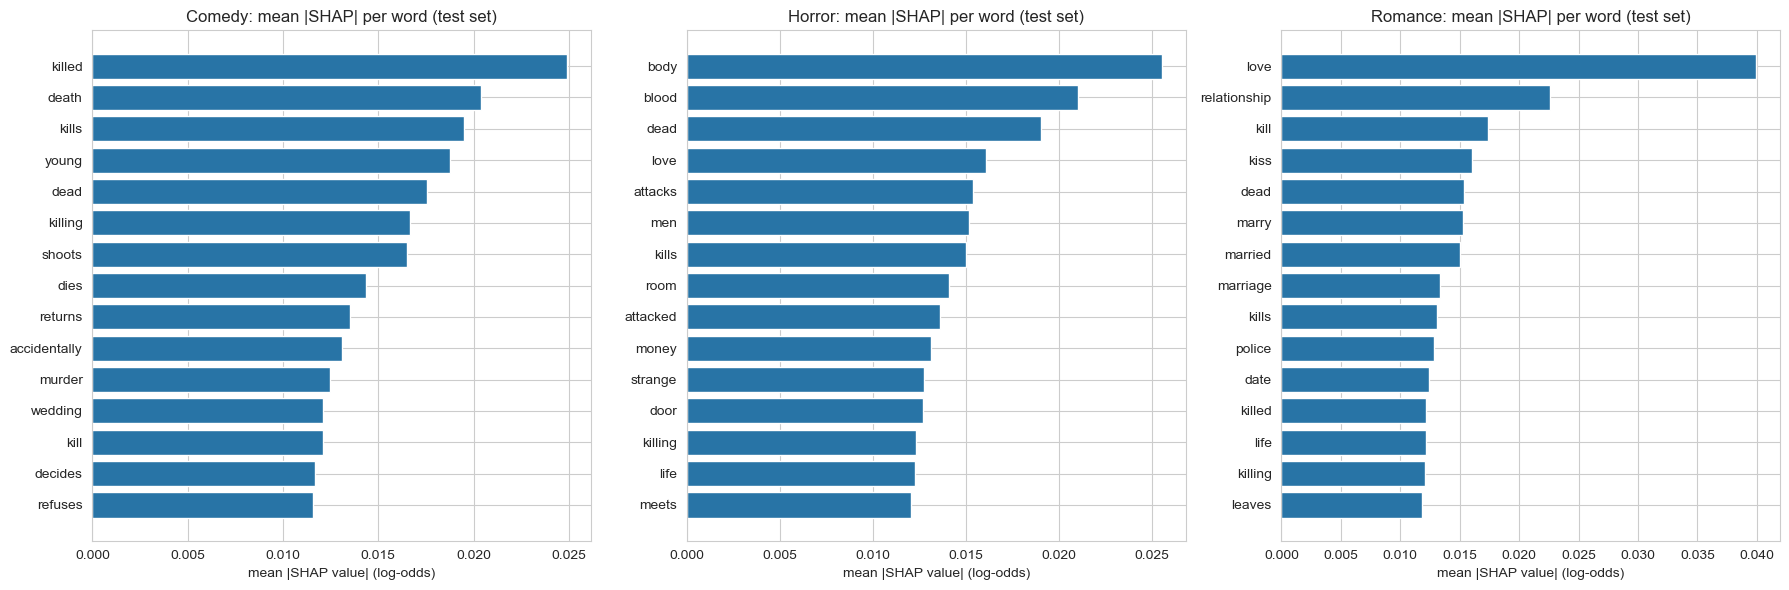

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, GENRES):
    top = shap_store[g]['mean_abs'].nlargest(15)[::-1]
    ax.barh(top.index, top.values, color='#2874a6')
    ax.set_title(f'{g}: mean |SHAP| per word (test set)')
    ax.set_xlabel('mean |SHAP value| (log-odds)')
plt.tight_layout()
plt.show()

### 3.2 Coefficients versus SHAP

The next cell puts the two rankings side by side. For each genre it lists the 10 words with the largest |coefficient| next to their SHAP rank and the share of test synopses that contain them, then summarizes how much the two rankings agree. The scatter plot shows every word: |coefficient| across, mean |SHAP| up, and the share of test synopses containing the word as the colour.

In [5]:
summary = []
for g in GENRES:
    ma = shap_store[g]['mean_abs']
    coef_rank = coefs[g].abs().rank(ascending=False).astype(int)
    shap_rank = ma.rank(ascending=False).astype(int)
    top10 = coefs[g].abs().nlargest(10).index
    print(f'=== {g}: the 10 words with the largest |coefficient|')
    print(pd.DataFrame({'coefficient': coefs[g][top10].round(3), 'coef rank': coef_rank[top10], 'mean |SHAP|': ma[top10].round(4),
                        'SHAP rank': shap_rank[top10], 'in % of test synopses': (doc_freq[top10] * 100).round(1)}).to_string())
    top20_coef = coefs[g].abs().nlargest(20).index
    top20_shap = ma.nlargest(20).index
    summary.append({'genre': g, 'Spearman |coef| vs mean |SHAP|': spearmanr(coefs[g].abs(), ma)[0],
                    'words in both top-20 lists': len(set(top20_coef) & set(top20_shap)),
                    'median % of synopses, top-20 by |coef|': 100 * doc_freq[top20_coef].median(),
                    'median % of synopses, top-20 by SHAP': 100 * doc_freq[top20_shap].median()})
    print(f"    top-10 by coefficient that are NOT in the top-20 by SHAP: {sorted(set(top10) - set(top20_shap))}\n")
pd.DataFrame(summary).set_index('genre').round(2)

=== Comedy: the 10 words with the largest |coefficient|
              coefficient  coef rank  mean |SHAP|  SHAP rank  in % of test synopses
killed             -0.028          1       0.0249          1                   41.2
kills              -0.024          2       0.0195          3                   27.1
death              -0.024          3       0.0204          2                   38.6
wedding             0.023          4       0.0121         12                    9.1
young              -0.022          5       0.0188          4                   36.3
shoots             -0.022          6       0.0165          7                   21.4
date                0.022          7       0.0104         24                    8.3
killing            -0.022          8       0.0166          6                   24.7
accidentally        0.021          9       0.0131         10                   13.3
dies               -0.021         10       0.0143          8                   16.7
    top-10 by coeffi

,Spearman |coef| vs mean |SHAP|,words in both top-20 lists,"median % of synopses, top-20 by |coef|","median % of synopses, top-20 by SHAP"
genre,,,,
Comedy,0.81,11,12.13,28.45
Horror,0.83,7,6.41,26.28
Romance,0.81,13,10.66,26.39


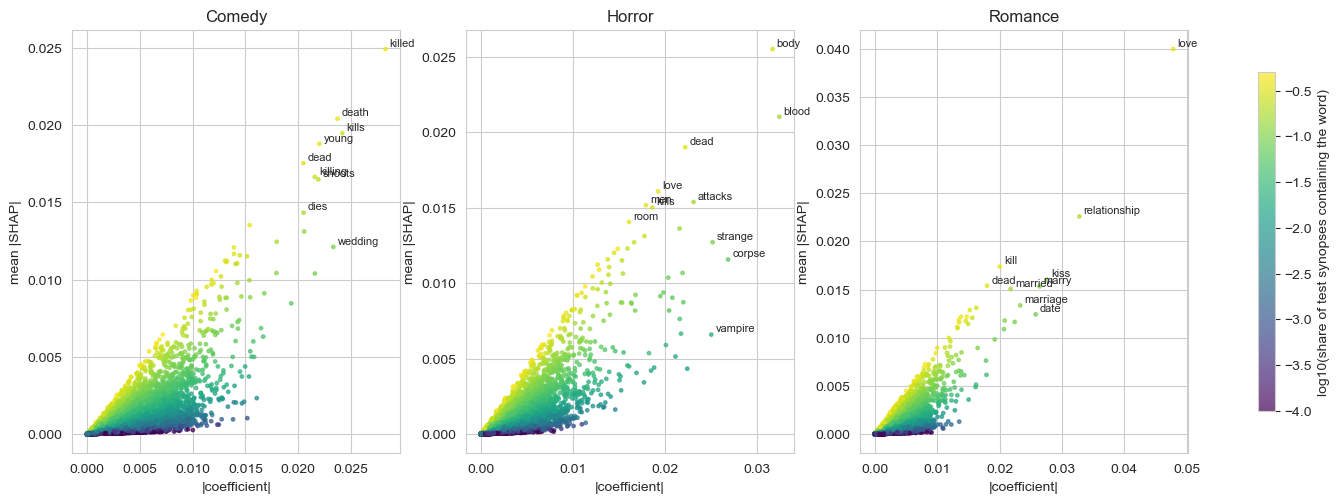

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, g in zip(axes, GENRES):
    ma = shap_store[g]['mean_abs']
    sc = ax.scatter(coefs[g].abs(), ma, c=np.log10(doc_freq.clip(lower=1e-4)), cmap='viridis', s=6, alpha=0.7)
    for w in ma.nlargest(8).index.union(coefs[g].abs().nlargest(5).index):
        ax.annotate(w, (abs(coefs[g][w]), ma[w]), fontsize=8, xytext=(3, 2), textcoords='offset points')
    ax.set_title(g)
    ax.set_xlabel('|coefficient|')
    ax.set_ylabel('mean |SHAP|')
fig.colorbar(sc, ax=axes, label='log10(share of test synopses containing the word)', shrink=0.8)
plt.show()

**How the rankings differ, and why.** The two rankings agree broadly (the rank correlation is about 0.8 for every genre), because a word needs a non-zero coefficient to matter at all. But they disagree at the top, in a consistent direction. The words with the largest coefficients are specific and **rare**: the top-20 coefficient words appear in a median of only about 6 to 12% of test synopses, while the top-20 SHAP words appear in about a quarter. A rare word can have a huge coefficient and still contribute almost nothing on average, because in most synopses its value is zero. Examples for Horror are `vampire`, `vampires` and `basement`, which sit high in the coefficient plot but fall far down the SHAP ranking (see the table above). In their place the SHAP bar plot is led by **common** words with moderate coefficients that are present in many synopses and so push in many predictions: `body`, `blood` and `dead` for Horror, `killed`, `death`, `kills` and `young` for Comedy, and `love` and `relationship` for Romance. Several words that did not even make the Horror coefficient top-10 (`men`, `room`, `door`, `money`) appear in its SHAP top-12 for the same reason.

The practical reading is that the coefficient plot answers "which words would convince the model, if they appeared?" and the SHAP bar plot answers "which words actually decided the predictions on real movies?". The second is the better description of the model in use. It also shows how much of the Comedy and Romance models is made of negative evidence: for Comedy, violence words such as `killed`, `death` and `kills` do more work than any comedic word.

### 3.3 Beeswarm plots

The beeswarm shows every test synopsis as a dot for each of the top words. A dot's horizontal position is that synopsis's SHAP value for the word (right pushes toward the genre, left pushes away), and its colour is the word's value in that synopsis (red = high TF-IDF, blue = low). Words are ordered by mean |SHAP|.

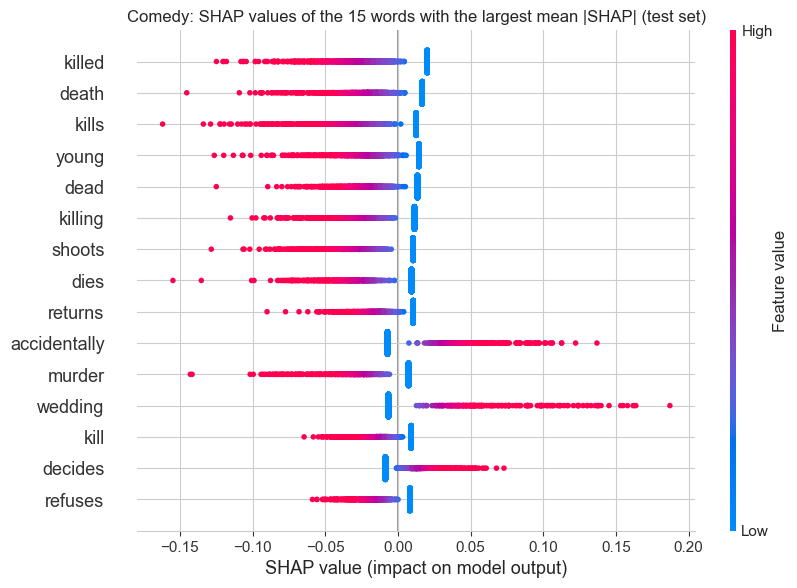

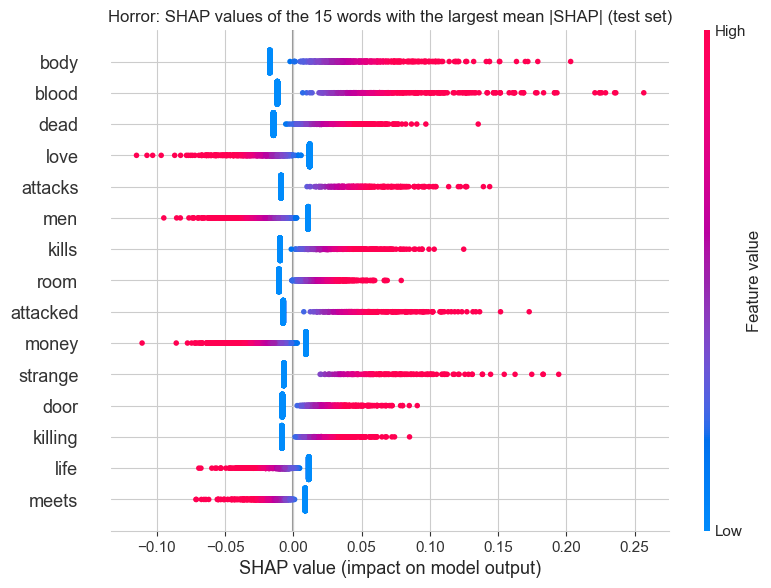

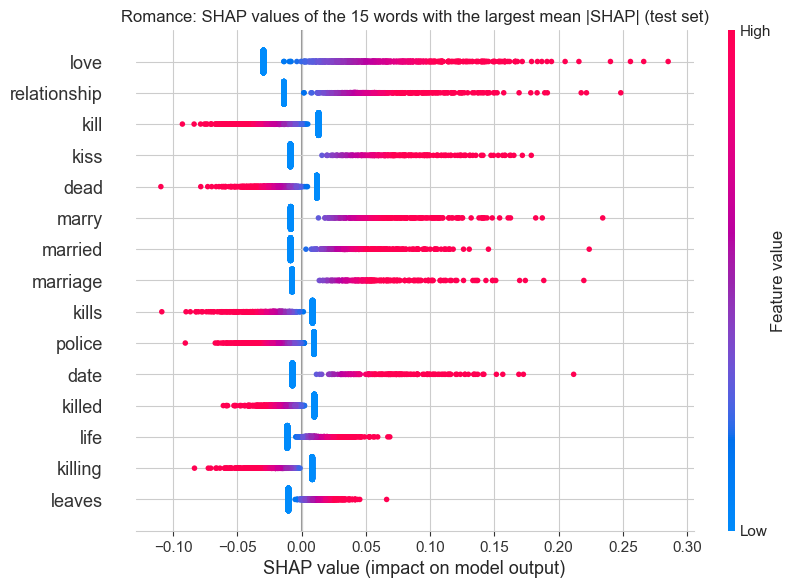

In [7]:
for g in GENRES:
    s = shap_store[g]
    explanation = shap.Explanation(values=s['top_values'], base_values=np.full(Xte.shape[0], s['explainer'].expected_value),
                                   data=s['top_data'], feature_names=list(vocab[s['top_idx']]))
    plt.title(f'{g}: SHAP values of the 15 words with the largest mean |SHAP| (test set)')
    shap.plots.beeswarm(explanation, max_display=15, show=False, plot_size=(9, 6.5))
    plt.show()

**What the beeswarm shows that the bar plot hides.** The bar plot gives one number per word, so it cannot show three things the beeswarm does.

1. **Direction.** A word's bar is the same length whether it pushes toward or away from the genre. In the beeswarm the red dots (the word is present) fall on one side of zero for nearly every word, which confirms the sign of the coefficient, for example `blood` and `body` pushing toward Horror and `love` pushing away from it.
2. **A few big pushes versus many small ones.** Most dots for a word are bunched near zero (the word is absent or barely present, and the contribution is small) and a minority of dots stretch far to one side. The mean in the bar plot averages these two very different groups together, so a word can look moderate while having a dramatic effect in the synopses where it is concentrated.
3. **Dose.** Within a word, the colour gradient shows that a higher TF-IDF value (the word is used more, in a shorter synopsis) pushes harder than a low one. A single coefficient gives the slope, but the beeswarm shows how many synopses are actually at each level.

The beeswarm also shows that SHAP values here are not symmetric around zero for a word that is absent. Because TF-IDF is not centred (`with_mean=False` in Notebook 2), the contribution of an absent word is `-coefficient x mean_j`, a small push in the opposite direction. This is why the "absent" dots are not exactly at zero.

## 4. Individual predictions

A waterfall plot explains one synopsis. It starts at the base value `E[f(x)]` (the average log-odds over the training set), adds each word's contribution one step at a time (red bars push toward the genre, blue bars push away) and ends at `f(x)`, the model's log-odds for this movie. A positive `f(x)` means the model predicts the genre. The 11 largest word contributions are drawn and the remaining ~19,989 words are grouped into one bar. The number to the left of each word is its standardized TF-IDF value in this synopsis (about 30 means the word is about 30 standard deviations above its training-set average, which is typical for a rare word).

Three test movies are shown. They were picked from the model's probabilities on the test set, and the cell prints the probability, the IMDB genres and the start of the plot so each case can be checked:

1. **Confidently right:** *Dead Alive*, a Horror movie that the Horror model scores at about 99%.
2. **Badly wrong, false alarm:** *Night of the Demons* (2009), which the Horror model scores at about 97% although IMDB does not list Horror for it.
3. **Badly wrong, miss:** *Hackers*, which IMDB lists as Romance but the Romance model scores at only about 6%.

The three were chosen as the extreme cases of their kind (the highest-probability correct Horror movie, and the most confident wrong Horror and Romance predictions).

confidently right: Dead Alive (Horror model)
  IMDB genres: Comedy, Fantasy, Horror | true Horror label: yes
  model probability of Horror: 0.989 | base value -1.122 -> f(x) +4.516
  plot starts: The first scene sets up the danger of the "Sumatran Rat-Monkey," a hybrid creature that "according to legend" resulted from the rape of tree monkeys on Skull Island by plague-carrying rats. Stewart, an explorer returning from the depths of the island with his guide and team, is carrying a rat-monkey...


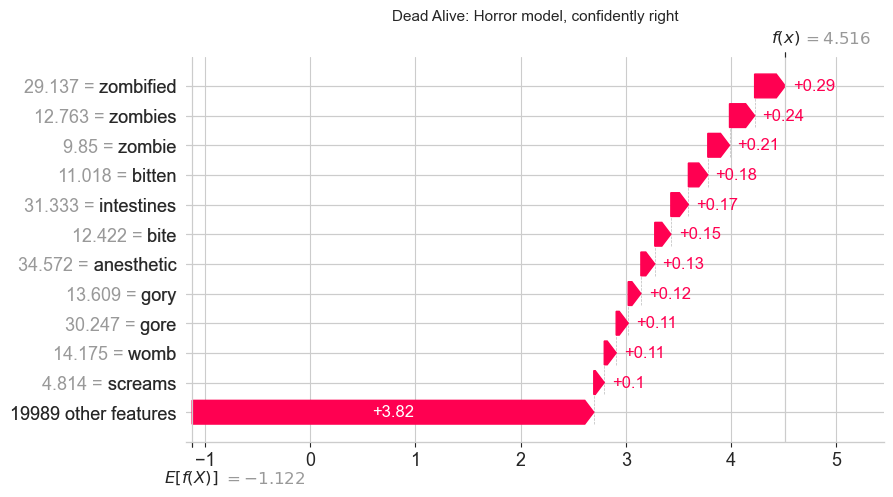

In [8]:
GENRE_COLUMNS = ['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Drama', 'Family', 'Fantasy', 'Horror', 'Musical',
                 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War']

def explain_movie(genre, imdb_id, label):
    i = test.index[test['imdb_id'] == imdb_id][0]
    row = test.loc[i]
    model, explainer = models[genre], shap_store[genre]['explainer']
    prob = model.predict_proba(Xte[i])[0, 1]
    values = explainer.shap_values(Xte[i])[0]
    print(f"{label}: {row['primaryTitle']} ({genre} model)")
    print(f"  IMDB genres: {', '.join(c for c in GENRE_COLUMNS if row[c] == 1)} | true {genre} label: {'yes' if row[genre] == 1 else 'no'}")
    print(f"  model probability of {genre}: {prob:.3f} | base value {explainer.expected_value:+.3f} -> f(x) {model.decision_function(Xte[i])[0]:+.3f}")
    print(f"  plot starts: {row['text'][:300].strip()}...")
    explanation = shap.Explanation(values=values, base_values=explainer.expected_value, data=Xte[i].toarray().ravel(), feature_names=list(vocab))
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f"{row['primaryTitle']}: {genre} model, {label}", fontsize=11)
    plt.gcf().set_size_inches(9, 5)
    plt.show()

explain_movie('Horror', 'tt0103873', 'confidently right')

badly wrong (false alarm): Night of the Demons (Horror model)
  IMDB genres: Action, Comedy, Fantasy | true Horror label: no
  model probability of Horror: 0.965 | base value -1.122 -> f(x) +3.322
  plot starts: Maddie Curtis and her friends Lilly and Suzanne are ready for a great Halloween night. Theyre going to a party thrown by their friend Angela at the notorious Broussard Mansion in New Orleans. Over eighty years ago, six people disappeared from the mansion without a trace and the owner, Evangeline Bro...


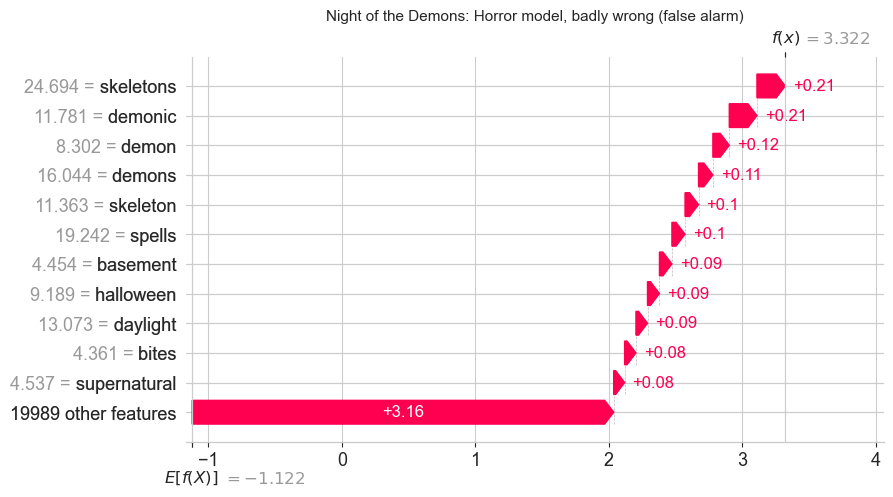

In [9]:
explain_movie('Horror', 'tt1268809', 'badly wrong (false alarm)')

badly wrong (miss): Hackers (Romance model)
  IMDB genres: Crime, Drama, Romance | true Romance label: yes
  model probability of Romance: 0.067 | base value -0.937 -> f(x) -2.632
  plot starts: In 1988, 11-year-old Dade "Zero Cool" Murphy is arrested and charged with crashing 1,507 computer systems in a single day and causing a single-day 7-point drop in the New York Stock Exchange. His family is fined $45,000 for the events and he is banned from using computers or touch-tone telephones un...


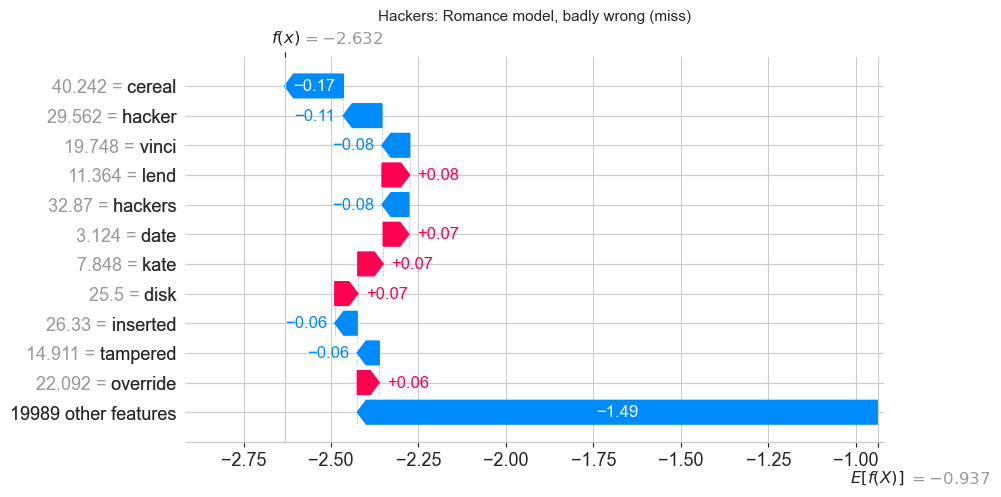

In [10]:
explain_movie('Romance', 'tt0113243', 'badly wrong (miss)')

**Reading the waterfalls.** One feature of all three plots comes first. The grouped bar of the other ~19,989 words is the largest single bar in each plot (about +3.8, +3.2 and -1.4). That is a direct result of the very strong regularization chosen in Notebook 2: every coefficient is tiny, so no individual word can dominate, and a prediction is made of a few visible words plus a long tail of thousands of small contributions that all lean the same way. The labelled words are therefore the clearest *examples* of the evidence, not the whole of it.

*Dead Alive (right).* The labelled words are a family of monster and gore words: `zombified`, `zombies`, `zombie`, `bitten`, `intestines`, `bite`, `gory`, `gore`. They all push toward Horror, none pushes against it noticeably, and the long tail of other words agrees (+3.8). The model reaches a log-odds of +4.5, about 99%, because the whole vocabulary of the synopsis points the same way, which is when a bag-of-words model is most reliable. The movie is also tagged Comedy and Fantasy, but the Horror model is not distracted by that.

*Night of the Demons (wrong, but arguably not the model's fault).* The labelled words are `skeletons`, `demonic`, `demon`, `demons`, `spells`, `basement`, `halloween` and `supernatural`, and the tail agrees (+3.2), so the model gives about 97% for Horror. IMDB lists this movie as Action, Comedy and Fantasy, so the "true" label is no. A reader of the plot would probably side with the model rather than the tag. This shows that part of the test error is **label noise**: IMDB genre tags are chosen by people and distributors, and a plot full of demons can still be marketed as a comedy. The model is following the vocabulary, and the vocabulary says Horror.

*Hackers (wrong, a genuine miss).* Here the tail pushes strongly away from Romance (-1.4), and the labelled words are technical: `hacker`, `hackers`, `transactions`, `inserted`, `tampered`, plus two odd ones, `cereal` and `vinci`, that come from specific scenes. The few words that lean toward Romance (`lend`, `date`, `kate`, `disk`) are tiny. IMDB lists Romance because a romance runs through the story, but a love story is not the main subject of the synopsis, so the vocabulary that would signal it is outnumbered by computer-crime words. This is the weakness of a bag-of-words model: it counts vocabulary and cannot tell a central romance from a side one. The same weakness helps explain why Romance is the hardest genre in Notebook 2.

## 5. Summary

- **What the models learned.** The coefficients are sensible. Horror is detected by concrete threat words, Romance by relationship words, and Comedy mostly by the absence of violence plus a few light social words. Horror has the strongest evidence and Comedy the weakest, matching the Notebook 2 scores.
- **Coefficient versus SHAP.** The largest coefficients belong to rare words, while the largest SHAP values belong to common words. The SHAP ranking is the more faithful picture of what drives predictions on real movies.
- **Where the models fail.** Some errors are label noise (a demon-filled movie not tagged Horror), and some are real limits of bag-of-words (a minor romance inside a crime plot). Neither is fixed by tuning `C` or `class_weight`. Better labels or a model that reads context would be needed.